# Requirement 1 -- Single-Campaign Bidding: UCB1 vs Budgeted UCB vs Exploration-Constant Variants

This notebook covers the full Requirement 1 experiments: one advertising campaign, bidding repeatedly in
first-price auctions against a stochastic competing bid, under a fixed budget.

Three experiments, in order:

1. The main configuration from `configs/req1.yaml` (T = 1000, B = 300): standard **UCB1** against the
   budget-aware, LP-paced **Budgeted UCB**, first for a single seed so we can actually see one run happen,
   then averaged over many seeds.
2. The same setup with a much tighter budget (B = 150), to see how much the budget constraint actually
   changes things once it starts binding harder.
3. The main configuration again, now comparing UCB1 and Budgeted UCB against two exploration-constant
   variants: **UCB1-Tuned** (Auer, Cesa-Bianchi & Fischer, 2002) and a **rescaled-constant UCB**, where the
   exploration term is rescaled using the best achievable expected reward instead of assuming rewards are
   bounded in [0, 1].

Everything below imports the real project code directly (`ola/algorithms/`, `ola/environments/`,
`experiments/run_req1.py`) so the numbers here match what the actual pipeline produces -- nothing is
reimplemented from scratch except the multi-seed aggregation and plotting, which don't exist yet elsewhere
in the project.

In [1]:
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / "ola").is_dir() and (candidate / "experiments").is_dir():
            return candidate
    raise RuntimeError("Could not locate project root (expected ola/ and experiments/ directories).")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from experiments.run_req1 import (
    expected_reward_for_uniform_competing_bid,
    compute_req1_benchmarks,
)
from ola.algorithms.ucb1 import UCB1
from ola.algorithms.budgeted_ucb import BudgetedUCB
from ola.algorithms.ucb_variants import (
    UCB1Tuned,
    ExpectedRewardScaledUCB,
    BudgetedUCB1Tuned,
    BudgetedExpectedRewardScaledUCB,
)
from ola.environments.single_campaign import SingleCampaignEnvironment

plt.rcParams["figure.dpi"] = 100

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/foadzahedilabaf/Projects/ola-project


## Setup, and a note on regret

Each round, the agent picks a bid from a fixed grid of 11 values (0.0 to 1.0 in steps of 0.1). The
environment draws the highest competing bid from `Uniform(min_competing_bid, max_competing_bid)`, and the
agent wins the round if its bid is at least as high. On a win it pays its own bid (first-price) and earns
`value - bid`; on a loss reward and cost are both 0.

For regret, I'm using **pseudo-regret**: at each round, I compare the benchmark's per-round expected reward
against the *expected* reward of the bid the agent actually chose (via the closed-form
`expected_reward_for_uniform_competing_bid` helper), not the noisy 0/1-win realized reward. Realized regret
carries a lot of extra Bernoulli sampling noise that has nothing to do with how well the algorithm is
learning -- especially over a horizon of only 1000 rounds -- so pseudo-regret gives a much cleaner picture
of actual convergence.

One more thing that matters a lot here: once an algorithm runs out of budget and stops early, the campaign
is genuinely over -- cumulative reward and budget left are real physical quantities, so those two flatten
out exactly where the run stopped. Regret is different. Every round the campaign *isn't* running is a round
it's earning 0 reward against a benchmark that's still worth `benchmark_reward_per_round`, so the regret
curves below keep climbing at the full per-round rate for every missing round, all the way out to the same
T = 1000 for every algorithm. If I froze the regret line the same way as budget and reward, an algorithm
that goes bankrupt early would look artificially *good* on the chart -- its line would just stop climbing
right when it's actually doing its worst. So: budget-left and cumulative-reward panels show what literally
happened; the regret panel shows the fair cost of that, extended to the full horizon.

In [2]:
with open(PROJECT_ROOT / "configs" / "req1.yaml", "r") as f:
    config = yaml.safe_load(f)

VALUE = float(config["campaign"]["value"])
BIDS = np.array(config["bids"]["values"], dtype=float)
MIN_CB = float(config["environment"]["min_competing_bid"])
MAX_CB = float(config["environment"]["max_competing_bid"])
DIST = config["environment"].get("competing_bid_distribution", "uniform")
N_COMP = int(config["environment"].get("n_competitors", 3))
HORIZON = int(config["experiment"]["horizon"])
BASE_ENV_SEED = int(config["experiment"]["random_seed"])
INITIAL_BUDGET_MAIN = float(config["campaign"]["initial_budget"])

ucb1_benchmark, budgeted_benchmark = compute_req1_benchmarks(
    bids=BIDS, value=VALUE, initial_budget=INITIAL_BUDGET_MAIN, horizon=HORIZON,
    min_competing_bid=MIN_CB, max_competing_bid=MAX_CB,
    competing_bid_distribution=DIST, n_competitors=N_COMP,
)

print(f"bids: {BIDS}")
print(f"value={VALUE}, horizon={HORIZON}, initial_budget={INITIAL_BUDGET_MAIN}")
print(f"competing bid ~ {DIST}({MIN_CB}, {MAX_CB})")
print(f"UCB1 benchmark (unconstrained best arm): {ucb1_benchmark:.4f}")
print(f"Budget-feasible benchmark (rho={INITIAL_BUDGET_MAIN/HORIZON:.3f}): {budgeted_benchmark:.4f}")

bids: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
value=1.0, horizon=1000, initial_budget=300.0
competing bid ~ uniform(0.1, 0.7)
UCB1 benchmark (unconstrained best arm): 0.3333
Budget-feasible benchmark (rho=0.300): 0.3250


## Algorithms, quickly

**UCB1** picks the bid with the highest `mean + sqrt(2 ln t / n)`. It has no idea a budget exists -- it
just keeps running until it literally can't afford the bid it wants to try next, at which point the
experiment loop stops it.

**Budgeted UCB** uses the same optimistic reward index, but instead of taking the arg-max directly, it
solves a small LP each round over the *reachable* bid mixtures given the budget left and the rounds
remaining, and samples from that distribution. That's what actually paces spending so the campaign survives
the full horizon.

Both are implemented once in `ola/algorithms/` and reused unmodified everywhere below.

In [3]:
def run_one_seed(learner, algorithm_name, is_budgeted, initial_budget, horizon,
                  env_seed, benchmark_reward_per_round, bids=BIDS, value=VALUE,
                  min_competing_bid=MIN_CB, max_competing_bid=MAX_CB,
                  competing_bid_distribution=DIST, n_competitors=N_COMP):
    """Run one learner against one environment seed.

    Tracks realized cumulative reward/cost/budget as usual, plus pseudo-regret
    (built from the closed-form expected reward of the chosen bid, not the
    noisy realized 0/1 win outcome) so we can see convergence without extra
    sampling noise on top of it.
    """
    env = SingleCampaignEnvironment(
        value=value, initial_budget=initial_budget, horizon=horizon,
        min_competing_bid=min_competing_bid, max_competing_bid=max_competing_bid,
        competing_bid_distribution=competing_bid_distribution, n_competitors=n_competitors,
        random_seed=env_seed,
    )
    env.reset()
    n_actions = len(bids)
    arm_counts = np.zeros(n_actions, dtype=int)
    action_index_history = []

    cumulative_reward = np.zeros(horizon)
    budget_left_trace = np.zeros(horizon)
    pseudo_cumulative_regret = np.zeros(horizon)

    running_reward = 0.0
    running_pseudo_regret = 0.0
    rounds_played = 0

    for t in range(horizon):
        action = learner.select_action()
        if float(action) > env.budget_left:
            break  # can't afford the bid it wants to try -- campaign is over
        outcome = env.step(action)
        reward = float(outcome["reward"])
        cost = float(outcome["cost"])

        if is_budgeted:
            learner.update(action=action, reward=reward, cost=cost)
        else:
            learner.update(action=action, reward=reward)

        arm_index = int(np.argmin(np.abs(bids - float(action))))
        arm_counts[arm_index] += 1
        action_index_history.append(arm_index)

        running_reward += reward
        pseudo_expected_reward = expected_reward_for_uniform_competing_bid(
            bid=float(action), value=value,
            min_competing_bid=min_competing_bid, max_competing_bid=max_competing_bid,
            competing_bid_distribution=competing_bid_distribution, n_competitors=n_competitors,
        )
        running_pseudo_regret += benchmark_reward_per_round - pseudo_expected_reward

        cumulative_reward[t] = running_reward
        budget_left_trace[t] = outcome["budget_left"]
        pseudo_cumulative_regret[t] = running_pseudo_regret
        rounds_played += 1

        if outcome["done"]:
            break

    # After an early stop, reward and budget are real physical quantities that
    # actually stop moving -- the campaign is dead, so those two freeze flat.
    # Regret is different: every round the campaign *isn't* running, it's
    # earning exactly 0 expected reward against a benchmark that's still
    # collecting benchmark_reward_per_round, so pseudo-regret keeps accruing
    # the full per-round penalty for each missing round. Freezing the regret
    # trace too would make an early bankruptcy look artificially good on the
    # chart -- it would flatten out low right when the algorithm is actually
    # doing its worst.
    if 0 < rounds_played < horizon:
        cumulative_reward[rounds_played:] = cumulative_reward[rounds_played - 1]
        budget_left_trace[rounds_played:] = budget_left_trace[rounds_played - 1]
        last_regret = pseudo_cumulative_regret[rounds_played - 1]
        missing_rounds = horizon - rounds_played
        penalty_ramp = benchmark_reward_per_round * np.arange(1, missing_rounds + 1)
        pseudo_cumulative_regret[rounds_played:] = last_regret + penalty_ramp
    elif rounds_played == 0:
        budget_left_trace[:] = initial_budget
        pseudo_cumulative_regret[:] = benchmark_reward_per_round * np.arange(1, horizon + 1)

    full_horizon_pseudo_regret = pseudo_cumulative_regret[-1]

    last_100_indices = action_index_history[-100:]
    last_100_counts = (np.bincount(last_100_indices, minlength=n_actions)
                        if last_100_indices else np.zeros(n_actions))

    return {
        "algorithm": algorithm_name,
        "rounds_played": rounds_played,
        "stopped_early": rounds_played < horizon,
        "final_budget_left": budget_left_trace[-1],
        "arm_counts": arm_counts,
        "last_100_counts": last_100_counts,
        "cumulative_reward": cumulative_reward,
        "budget_left": budget_left_trace,
        "pseudo_cumulative_regret": pseudo_cumulative_regret,
        "full_horizon_pseudo_regret": full_horizon_pseudo_regret,
    }

In [4]:
def multi_seed_run(learner_factory, algorithm_name, is_budgeted, n_seeds, base_env_seed,
                    initial_budget, horizon, benchmark_reward_per_round):
    """Run the same algorithm across n_seeds independent environment draws.

    learner_factory(env_seed) must return a fresh learner instance. Learner
    RNGs (for the budgeted algorithms) are decorrelated from the environment
    RNG using the same offset convention as experiments/run_req1.py.
    """
    results = []
    for i in range(n_seeds):
        env_seed = base_env_seed + i
        learner = learner_factory(env_seed)
        results.append(run_one_seed(
            learner=learner, algorithm_name=algorithm_name, is_budgeted=is_budgeted,
            initial_budget=initial_budget, horizon=horizon, env_seed=env_seed,
            benchmark_reward_per_round=benchmark_reward_per_round,
        ))
    return results

N_SEEDS = 30
print(f"n_seeds = {N_SEEDS}")

n_seeds = 30


In [5]:
LABELS = {
    "ucb1": "UCB1",
    "budgeted_ucb": "Budgeted UCB",
    "ucb1_tuned": "UCB1-Tuned",
    "expected_reward_scaled_ucb": "Rescaled-Constant UCB",
    "budgeted_ucb1_tuned": "Budgeted UCB1-Tuned",
    "budgeted_expected_reward_scaled_ucb": "Budgeted Rescaled-Constant UCB",
}
COLORS = {
    "ucb1": "#1f77b4",
    "budgeted_ucb": "#d62728",
    "ucb1_tuned": "#2ca02c",
    "expected_reward_scaled_ucb": "#9467bd",
    "budgeted_ucb1_tuned": "#ff7f0e",
    "budgeted_expected_reward_scaled_ucb": "#17becf",
}

def aggregate_multi(results_list):
    return {
        "cum_reward": np.stack([r["cumulative_reward"] for r in results_list]),
        "budget_left": np.stack([r["budget_left"] for r in results_list]),
        "pseudo_regret": np.stack([r["pseudo_cumulative_regret"] for r in results_list]),
        "arm_counts": np.stack([r["arm_counts"] for r in results_list]),
        "last_100_counts": np.stack([r["last_100_counts"] for r in results_list]),
    }

def plot_panel(data, algo_names, mode, title, bids=BIDS):
    """data: {algo_name: single result dict} if mode='single', else {algo_name: [result dicts]} if mode='multi'."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
    fig.suptitle(title, fontsize=13, fontweight="bold")
    ax_arms, ax_reward, ax_budget, ax_regret = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]
    n_actions = len(bids)
    bar_width = 0.8 / len(algo_names)

    for i, name in enumerate(algo_names):
        color, label = COLORS[name], LABELS[name]
        if mode == "single":
            r = data[name]
            rounds = np.arange(1, len(r["cumulative_reward"]) + 1)
            ax_reward.plot(rounds, r["cumulative_reward"], color=color, label=label)
            ax_budget.plot(rounds, r["budget_left"], color=color, label=label)
            ax_regret.plot(rounds, r["pseudo_cumulative_regret"], color=color, label=label)
            ax_arms.bar(np.arange(n_actions) + i * bar_width, r["arm_counts"], width=bar_width, color=color, label=label)
        else:
            agg = aggregate_multi(data[name])
            rounds = np.arange(1, agg["cum_reward"].shape[1] + 1)
            for key, ax in [("cum_reward", ax_reward), ("budget_left", ax_budget), ("pseudo_regret", ax_regret)]:
                mean, std = agg[key].mean(axis=0), agg[key].std(axis=0)
                ax.plot(rounds, mean, color=color, label=label)
                lower = np.maximum(0, mean - std) if key == "budget_left" else mean - std
                ax.fill_between(rounds, lower, mean + std, color=color, alpha=0.18)
            arm_mean, arm_std = agg["arm_counts"].mean(axis=0), agg["arm_counts"].std(axis=0)
            ax_arms.bar(np.arange(n_actions) + i * bar_width, arm_mean, width=bar_width, yerr=arm_std,
                        color=color, label=label, capsize=2)

    ax_arms.set_xticks(np.arange(n_actions) + bar_width * (len(algo_names) - 1) / 2)
    ax_arms.set_xticklabels([f"{b:.1f}" for b in bids])
    ax_arms.set_xlabel("bid"); ax_arms.set_ylabel("times played"); ax_arms.set_title("Arm-pull distribution")
    ax_reward.set_xlabel("round"); ax_reward.set_ylabel("cumulative reward"); ax_reward.set_title("Cumulative reward")
    ax_budget.set_xlabel("round"); ax_budget.set_ylabel("budget left"); ax_budget.set_title("Budget left")
    ax_regret.set_xlabel("round"); ax_regret.set_ylabel("cumulative pseudo-regret"); ax_regret.set_title("Cumulative pseudo-regret")
    for ax in (ax_arms, ax_reward, ax_budget, ax_regret):
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

def build_report(data_multi, algo_names, initial_budget, horizon):
    rows = []
    for name in algo_names:
        results = data_multi[name]
        n = len(results)
        stopped = sum(r["stopped_early"] for r in results)
        mean_budget_left = np.mean([r["final_budget_left"] for r in results])
        rows.append({
            "algorithm": LABELS[name],
            "seeds stopped early": f"{stopped}/{n}",
            "mean rounds played": round(float(np.mean([r["rounds_played"] for r in results])), 1),
            "mean budget left": round(float(mean_budget_left), 3),
            "budget utilization %": round(float((initial_budget - mean_budget_left) / initial_budget * 100), 2),
            "mean full-horizon pseudo-regret": round(float(np.mean([r["full_horizon_pseudo_regret"] for r in results])), 2),
            "std full-horizon pseudo-regret": round(float(np.std([r["full_horizon_pseudo_regret"] for r in results])), 2),
        })
    return pd.DataFrame(rows)

## Experiment 1 -- T = 1000, B = 300 (main config)

This matches `configs/req1.yaml` exactly. With `value = 1.0` and competing bids in
`Uniform(0.1, 0.7)`, the best single bid has expected reward **0.333**. The budget-feasible
benchmark, which also has to respect `rho = B/T = 0.30` spending per round, comes out slightly lower at
**0.325**.

In [6]:
SINGLE_SEED = BASE_ENV_SEED  # 42, matches configs/req1.yaml

single_results_p1 = {
    "ucb1": run_one_seed(
        UCB1(actions=BIDS, horizon=HORIZON), "ucb1", False,
        INITIAL_BUDGET_MAIN, HORIZON, SINGLE_SEED, ucb1_benchmark,
    ),
    "budgeted_ucb": run_one_seed(
        BudgetedUCB(actions=BIDS, horizon=HORIZON, initial_budget=INITIAL_BUDGET_MAIN,
                    random_seed=SINGLE_SEED + 1_000_003),
        "budgeted_ucb", True, INITIAL_BUDGET_MAIN, HORIZON, SINGLE_SEED, budgeted_benchmark,
    ),
}

for name, r in single_results_p1.items():
    print(f"{LABELS[name]:16s} rounds_played={r['rounds_played']:4d}  stopped_early={str(r['stopped_early']):5s}  "
          f"final_budget_left={r['final_budget_left']:.3f}  final_reward={r['cumulative_reward'][-1]:.2f}")

UCB1             rounds_played= 702  stopped_early=True   final_budget_left=0.400  final_reward=165.40
Budgeted UCB     rounds_played=1000  stopped_early=False  final_budget_left=0.000  final_reward=231.00


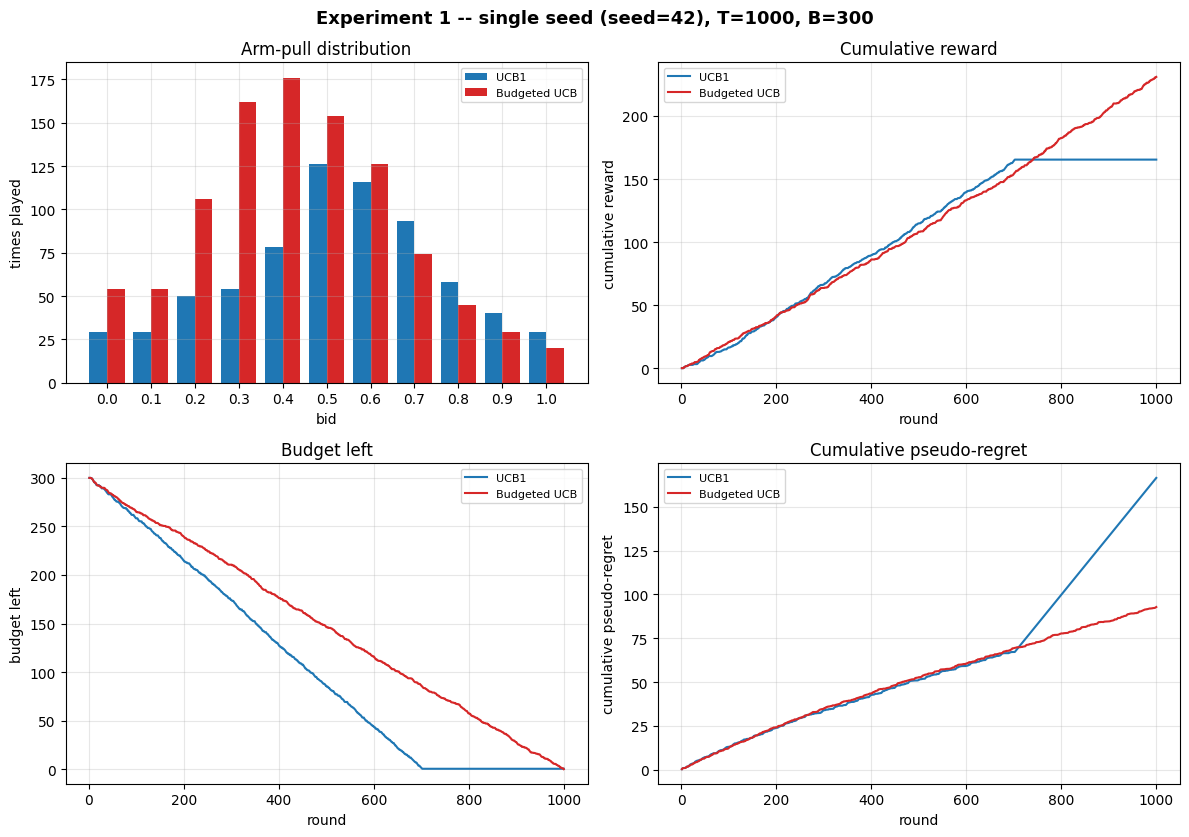

In [7]:
plot_panel(single_results_p1, ["ucb1", "budgeted_ucb"], mode="single",
           title="Experiment 1 -- single seed (seed=42), T=1000, B=300")

With seed 42, plain UCB1 runs out of money at **round 702**, ending with only 0.40 left
in the budget and a total realized reward of 165.4. Budgeted UCB survives the entire 1000
rounds and ends with 231.0 -- noticeably more, mostly just because it's still playing for the
~298 rounds that UCB1 already went bankrupt in.

You can see it clearly in the budget-left panel: UCB1's line goes flat the moment it hits the wall, while
Budgeted UCB's line glides down and lands almost exactly on 0 right around round 1000 -- that's the LP
pacing doing its job.

In [8]:
multi_results_p1 = {
    "ucb1": multi_seed_run(
        lambda s: UCB1(actions=BIDS, horizon=HORIZON), "ucb1", False,
        N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, ucb1_benchmark,
    ),
    "budgeted_ucb": multi_seed_run(
        lambda s: BudgetedUCB(actions=BIDS, horizon=HORIZON, initial_budget=INITIAL_BUDGET_MAIN,
                               random_seed=s + 1_000_003),
        "budgeted_ucb", True, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, budgeted_benchmark,
    ),
}
print(f"Ran {N_SEEDS} seeds for each of {list(multi_results_p1.keys())}")

Ran 30 seeds for each of ['ucb1', 'budgeted_ucb']


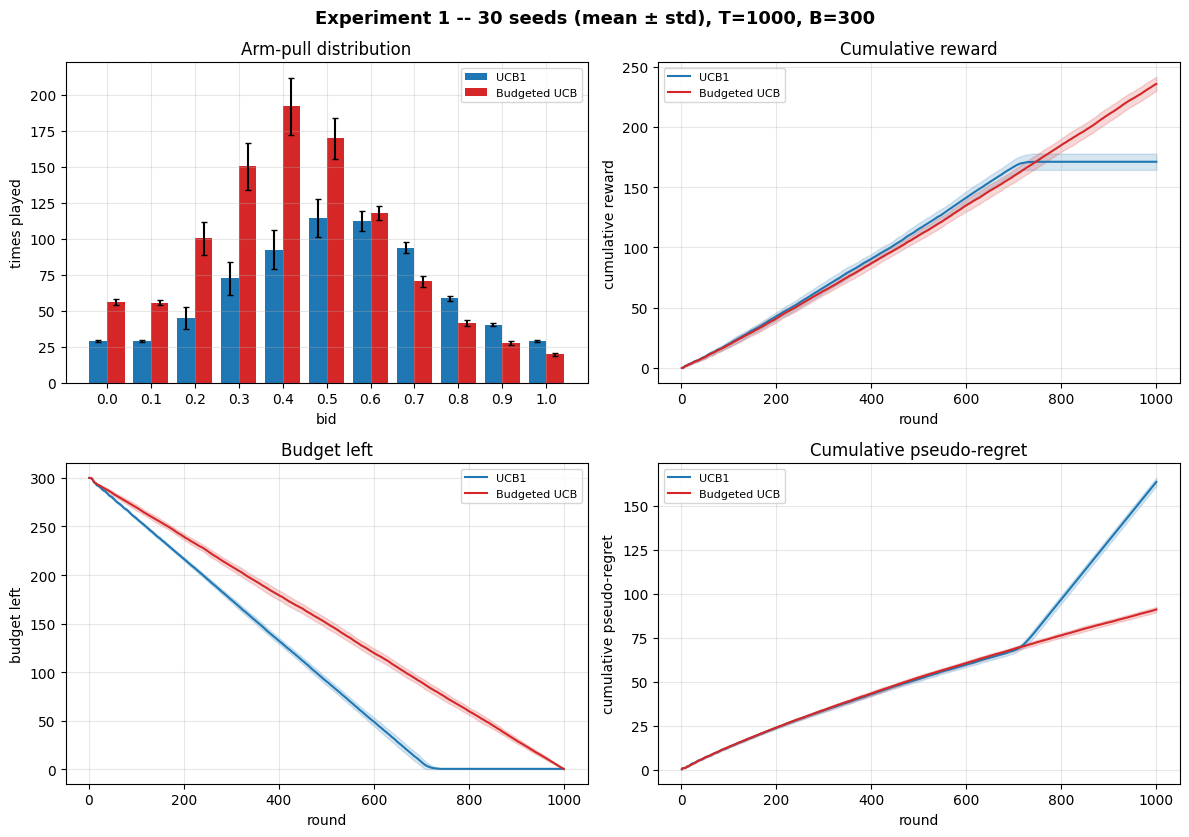

In [9]:
plot_panel(multi_results_p1, ["ucb1", "budgeted_ucb"], mode="multi",
           title=f"Experiment 1 -- {N_SEEDS} seeds (mean \u00b1 std), T=1000, B=300")

In [10]:
report_p1 = build_report(multi_results_p1, ["ucb1", "budgeted_ucb"], INITIAL_BUDGET_MAIN, HORIZON)
report_p1

,algorithm,seeds stopped early,mean rounds played,mean budget left,budget utilization %,mean full-horizon pseudo-regret,std full-horizon pseudo-regret
0,UCB1,30/30,716.1,0.310,99.90,163.43,2.32
1,Budgeted UCB,0/30,1000.0,0.163,99.95,91.06,1.54


Averaged over 30 seeds, UCB1 goes bankrupt around **round 716** on average, having already
used 99.90% of its budget by then. Budgeted UCB uses 99.95% of its budget too, but
spreads it across the full 1000 rounds instead of front-loading it.

Once each algorithm is fairly charged for the rounds it missed (the "full-horizon" column above), the
picture is honest and pretty decisive: UCB1 ends up with **163.4** average regret, Budgeted UCB
with **91.1**. Budgeted UCB isn't smarter about which arm is best -- if anything its LP pacing
makes it *more* conservative early on -- it just doesn't die halfway through the campaign.

## Experiment 2 -- T = 1000, B = 150 (tight budget)

Same setup, but the budget drops to 150, so `rho = 0.15` per round instead of 0.30. Let's see how much
harder that hits an algorithm that isn't even trying to pace itself.

In [11]:
INITIAL_BUDGET_TIGHT = 150.0

ucb1_benchmark_150, budgeted_benchmark_150 = compute_req1_benchmarks(
    bids=BIDS, value=VALUE, initial_budget=INITIAL_BUDGET_TIGHT, horizon=HORIZON,
    min_competing_bid=MIN_CB, max_competing_bid=MAX_CB,
    competing_bid_distribution=DIST, n_competitors=N_COMP,
)
print(f"B=150 benchmarks -> UCB1: {ucb1_benchmark_150:.4f}, budget-feasible: {budgeted_benchmark_150:.4f} "
      f"(rho={INITIAL_BUDGET_TIGHT/HORIZON:.3f})")

multi_results_p2 = {
    "ucb1": multi_seed_run(
        lambda s: UCB1(actions=BIDS, horizon=HORIZON), "ucb1", False,
        N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_TIGHT, HORIZON, ucb1_benchmark_150,
    ),
    "budgeted_ucb": multi_seed_run(
        lambda s: BudgetedUCB(actions=BIDS, horizon=HORIZON, initial_budget=INITIAL_BUDGET_TIGHT,
                               random_seed=s + 1_000_003),
        "budgeted_ucb", True, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_TIGHT, HORIZON, budgeted_benchmark_150,
    ),
}

B=150 benchmarks -> UCB1: 0.3333, budget-feasible: 0.2667 (rho=0.150)


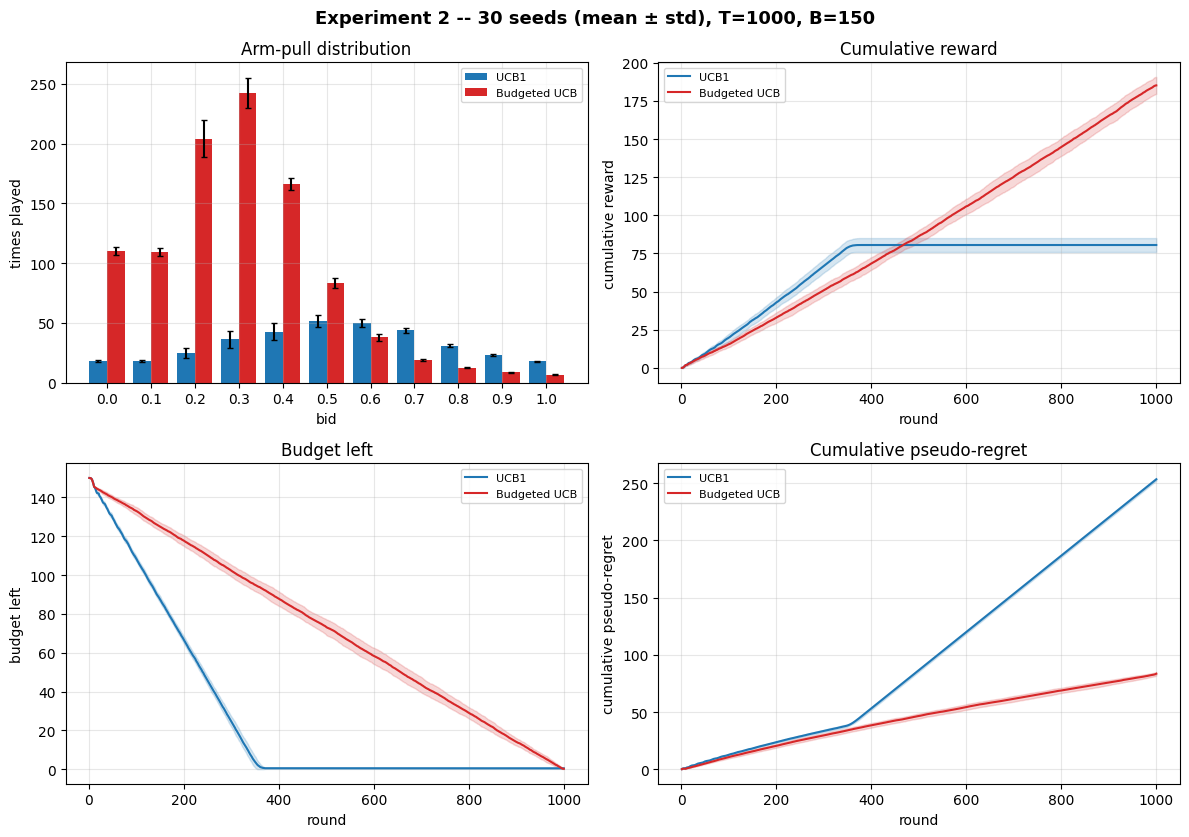

In [12]:
plot_panel(multi_results_p2, ["ucb1", "budgeted_ucb"], mode="multi",
           title=f"Experiment 2 -- {N_SEEDS} seeds (mean \u00b1 std), T=1000, B=150")

In [13]:
report_p2 = build_report(multi_results_p2, ["ucb1", "budgeted_ucb"], INITIAL_BUDGET_TIGHT, HORIZON)
report_p2

,algorithm,seeds stopped early,mean rounds played,mean budget left,budget utilization %,mean full-horizon pseudo-regret,std full-horizon pseudo-regret
0,UCB1,30/30,356.8,0.443,99.70,253.34,1.22
1,Budgeted UCB,0/30,1000.0,0.193,99.87,83.59,1.60


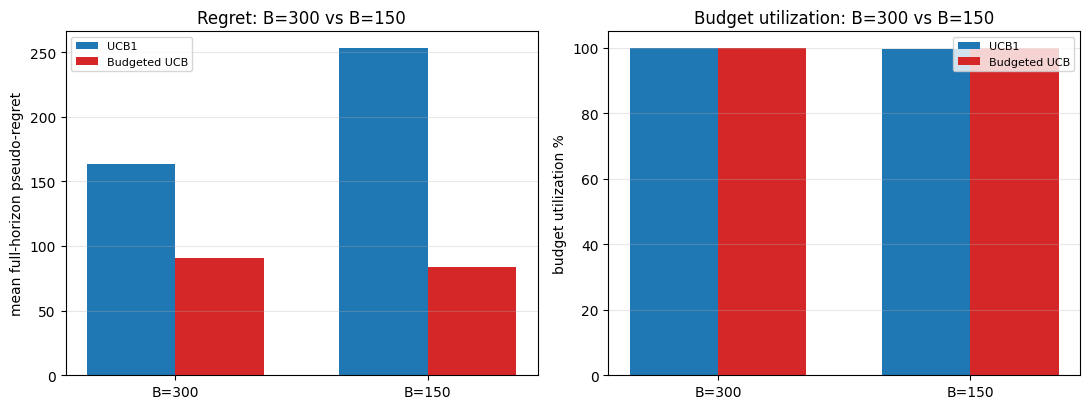

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
budgets = ["B=300", "B=150"]
x = np.arange(len(budgets))
width = 0.35

for i, name in enumerate(["ucb1", "budgeted_ucb"]):
    fh_means = [report_p1.loc[report_p1["algorithm"] == LABELS[name], "mean full-horizon pseudo-regret"].item(),
                report_p2.loc[report_p2["algorithm"] == LABELS[name], "mean full-horizon pseudo-regret"].item()]
    util_means = [report_p1.loc[report_p1["algorithm"] == LABELS[name], "budget utilization %"].item(),
                  report_p2.loc[report_p2["algorithm"] == LABELS[name], "budget utilization %"].item()]
    axes[0].bar(x + i * width, fh_means, width=width, color=COLORS[name], label=LABELS[name])
    axes[1].bar(x + i * width, util_means, width=width, color=COLORS[name], label=LABELS[name])

axes[0].set_xticks(x + width / 2); axes[0].set_xticklabels(budgets)
axes[0].set_ylabel("mean full-horizon pseudo-regret"); axes[0].set_title("Regret: B=300 vs B=150")
axes[1].set_xticks(x + width / 2); axes[1].set_xticklabels(budgets)
axes[1].set_ylabel("budget utilization %"); axes[1].set_title("Budget utilization: B=300 vs B=150")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

Cutting the budget in half roughly halves how long UCB1 survives -- it now goes bankrupt at **round
357** on average (versus 716 under B=300), and its full-horizon regret
climbs to **253.3** (from 163.4).

Budgeted UCB still finishes all 1000 rounds under the tighter budget, and its full-horizon regret
actually comes out a bit *lower* here (83.6) than under B=300 (91.1). That's
not because it's performing better in absolute terms -- its average reward per round drops from
0.236 to 0.185 -- it's because the benchmark itself is lower under B=150
(0.267 vs 0.325 per round), so there's simply less regret left on the table to accumulate
against a weaker target. Raw regret numbers from two different budget settings aren't directly comparable
unless you also look at the benchmark each one is being measured against.

Bottom line: UCB1's blindness to the budget gets punished harder as the budget gets tighter, while Budgeted
UCB's LP pacing keeps it alive regardless -- it just re-solves for a smaller `rho` every round.

## Experiment 3 -- T = 1000, B = 300, exploration-constant variants

Back to the main config, now comparing UCB1 and Budgeted UCB against two variants that change how the
exploration bonus is computed. Both a budget-free and a budget-aware version of each variant are
implemented in `ola/algorithms/ucb_variants.py`, reusing the same LP-pacing logic as `BudgetedUCB` for the
budget-aware side. I'll look at the two budget-free variants first, on their own, and only bring the budget
constraint back in afterward -- that way it's clear how much of any improvement comes from the exploration
bonus itself versus from budget pacing.

**UCB1-Tuned** (Auer, Cesa-Bianchi & Fischer, 2002) replaces the fixed `sqrt(2 ln t / n)` bonus with a
per-arm, variance-adaptive one:

`index_i(t) = mean_i + sqrt( (ln t / n_i) * min(1/4, V_i(n_i)) )`

where `V_i` is an upper-confidence estimate of that specific arm's own variance, capped at 1/4 (the maximum
possible variance for a reward bounded in [0,1]). Arms whose observed rewards are consistently close
together get a smaller exploration bonus, instead of every arm getting the same fixed one under plain
UCB1. There's no proven finite-time regret bound for this variant, but it's well documented empirically to
converge faster.

**Rescaled-constant UCB** keeps UCB1's exact structure, but rescales the constant inside the square root.
The standard derivation assumes rewards live in `[0, 1]`, which gives the constant 2. But in this
environment the *best achievable expected reward* is only 0.333, so the idea is to rescale:
`inner_constant = 2 * (max_expected_reward)^2`. Worth being honest about the catch here: this bounds the
*best arm's expected* reward, not the *realized, single-round* reward of the specific arm being estimated --
which is what Hoeffding's inequality actually requires. For this environment that per-arm bound is
`value - bid`, which ranges up to 1.0 regardless of which arm you're looking at, and has nothing to do with
the best arm's expected value. So this variant, like UCB1-Tuned, is an empirically-motivated heuristic
rather than something with a proven regret guarantee -- it's included here for the side-by-side comparison,
not as a replacement for canonical UCB1.

### 3a -- Without the budget constraint

Plain UCB1 against the two budget-free variants. All three still run inside the same environment (so they
can still go bankrupt and get cut off -- that part of the harness doesn't change), but none of them is
pacing its spending on purpose.

In [15]:
def make_ucb1_tuned(env_seed):
    return UCB1Tuned(actions=BIDS, horizon=HORIZON)

def make_rescaled(env_seed):
    return ExpectedRewardScaledUCB(actions=BIDS, horizon=HORIZON, max_expected_reward=ucb1_benchmark)

multi_results_p3_free = {"ucb1": multi_results_p1["ucb1"]}  # reuse the UCB1 run from Experiment 1 (same B=300)
multi_results_p3_free["ucb1_tuned"] = multi_seed_run(
    make_ucb1_tuned, "ucb1_tuned", False, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, ucb1_benchmark,
)
multi_results_p3_free["expected_reward_scaled_ucb"] = multi_seed_run(
    make_rescaled, "expected_reward_scaled_ucb", False, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, ucb1_benchmark,
)

rescaled_inner_constant = ExpectedRewardScaledUCB(actions=BIDS, horizon=HORIZON, max_expected_reward=ucb1_benchmark).inner_constant
print(f"rescaled exploration constant = 2 * ({ucb1_benchmark:.4f})^2 = {rescaled_inner_constant:.4f}  (vs UCB1's fixed 2.0)")

rescaled exploration constant = 2 * (0.3333)^2 = 0.2222  (vs UCB1's fixed 2.0)


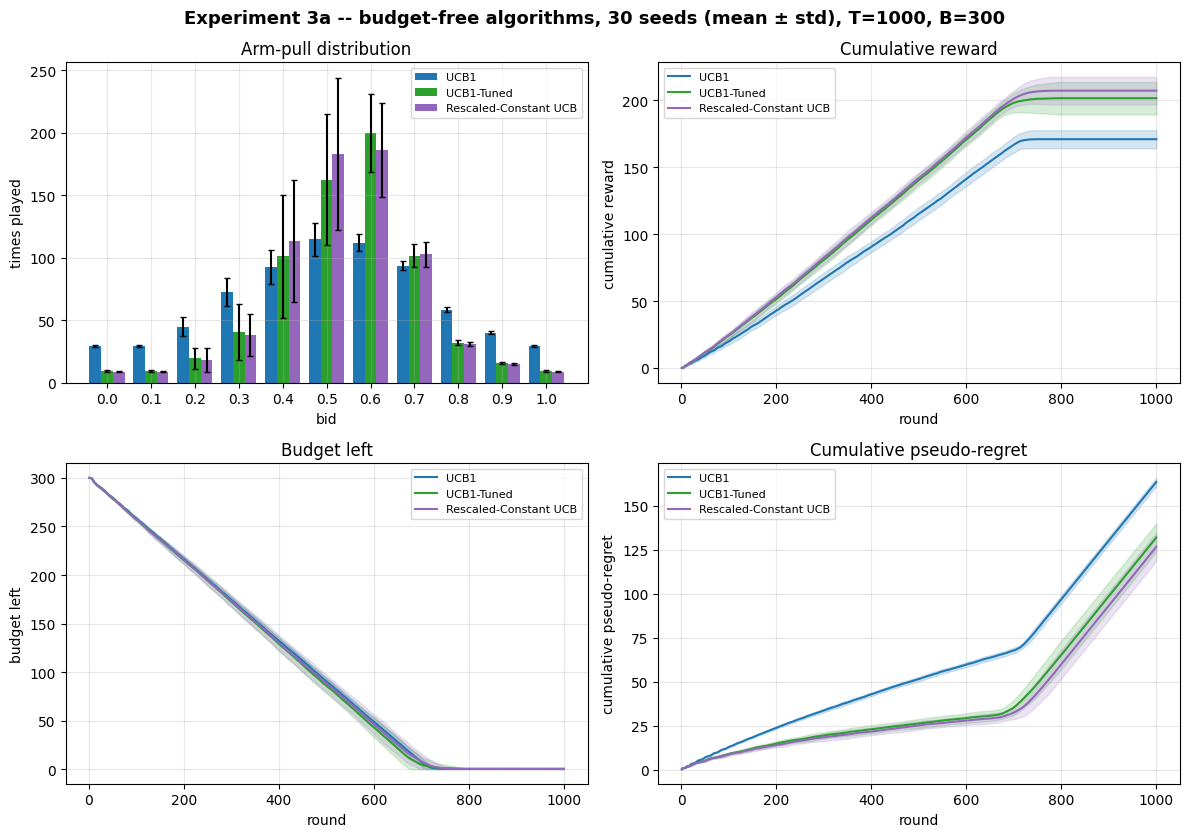

In [16]:
plot_panel(multi_results_p3_free, ["ucb1", "ucb1_tuned", "expected_reward_scaled_ucb"], mode="multi",
           title=f"Experiment 3a -- budget-free algorithms, {N_SEEDS} seeds (mean \u00b1 std), T=1000, B=300")

In [17]:
report_p3_free = build_report(multi_results_p3_free, ["ucb1", "ucb1_tuned", "expected_reward_scaled_ucb"],
                               INITIAL_BUDGET_MAIN, HORIZON)
report_p3_free

,algorithm,seeds stopped early,mean rounds played,mean budget left,budget utilization %,mean full-horizon pseudo-regret,std full-horizon pseudo-regret
0,UCB1,30/30,716.1,0.310,99.90,163.43,2.32
1,UCB1-Tuned,30/30,700.4,0.250,99.92,131.89,8.06
2,Rescaled-Constant UCB,30/30,713.5,0.193,99.94,126.57,8.01


Without any budget pacing, both variants still beat plain UCB1 by a solid margin. Full-horizon pseudo-regret
drops from **163.4** (UCB1) to **131.9** (UCB1-Tuned) and **126.6**
(rescaled-constant) -- essentially tied with each other, well within one standard deviation. That gap is
coming entirely from the exploration bonus itself: all three are equally blind to the budget, so this isolates
what the tuned/rescaled exploration terms buy on their own, before pacing gets added back in below.

### 3b -- With the budget constraint

Same two variants, now with the LP-pacing logic from `BudgetedUCB` added on top (`BudgetedUCB1Tuned` and
`BudgetedExpectedRewardScaledUCB`), compared against `BudgetedUCB` itself.

In [18]:
def make_budgeted_ucb1_tuned(env_seed):
    return BudgetedUCB1Tuned(actions=BIDS, horizon=HORIZON, initial_budget=INITIAL_BUDGET_MAIN,
                              random_seed=env_seed + 2_000_003)

def make_budgeted_rescaled(env_seed):
    return BudgetedExpectedRewardScaledUCB(actions=BIDS, horizon=HORIZON, initial_budget=INITIAL_BUDGET_MAIN,
                                            max_expected_reward=ucb1_benchmark, random_seed=env_seed + 3_000_003)

multi_results_p3_budgeted = {"budgeted_ucb": multi_results_p1["budgeted_ucb"]}
multi_results_p3_budgeted["budgeted_ucb1_tuned"] = multi_seed_run(
    make_budgeted_ucb1_tuned, "budgeted_ucb1_tuned", True, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, budgeted_benchmark,
)
multi_results_p3_budgeted["budgeted_expected_reward_scaled_ucb"] = multi_seed_run(
    make_budgeted_rescaled, "budgeted_expected_reward_scaled_ucb", True, N_SEEDS, BASE_ENV_SEED, INITIAL_BUDGET_MAIN, HORIZON, budgeted_benchmark,
)

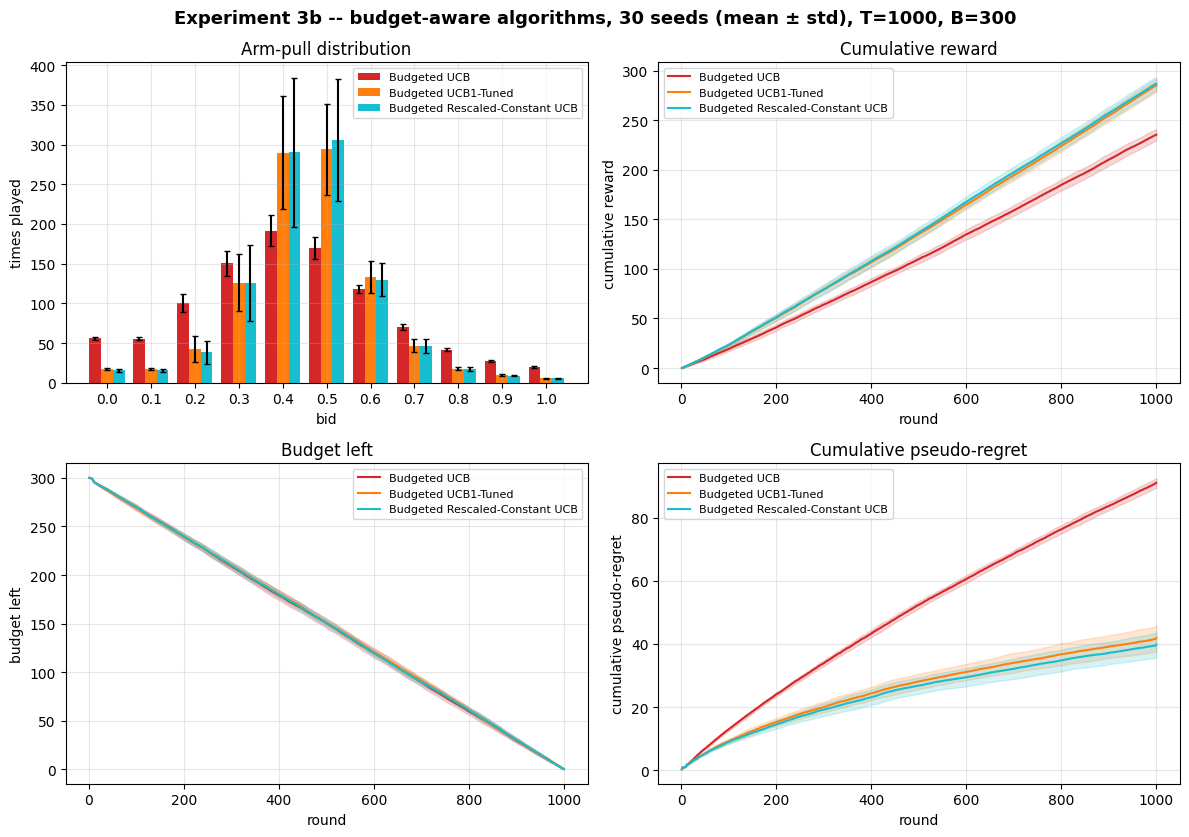

In [19]:
plot_panel(multi_results_p3_budgeted, ["budgeted_ucb", "budgeted_ucb1_tuned", "budgeted_expected_reward_scaled_ucb"], mode="multi",
           title=f"Experiment 3b -- budget-aware algorithms, {N_SEEDS} seeds (mean \u00b1 std), T=1000, B=300")

In [20]:
report_p3_budgeted = build_report(multi_results_p3_budgeted,
                                   ["budgeted_ucb", "budgeted_ucb1_tuned", "budgeted_expected_reward_scaled_ucb"],
                                   INITIAL_BUDGET_MAIN, HORIZON)
report_p3_budgeted

,algorithm,seeds stopped early,mean rounds played,mean budget left,budget utilization %,mean full-horizon pseudo-regret,std full-horizon pseudo-regret
0,Budgeted UCB,0/30,1000.0,0.163,99.95,91.06,1.54
1,Budgeted UCB1-Tuned,0/30,1000.0,0.147,99.95,41.87,4.05
2,Budgeted Rescaled-Constant UCB,0/30,1000.0,0.177,99.94,39.83,3.98


With pacing added back in, the same pattern holds and the gap gets even bigger: full-horizon pseudo-regret
drops from **91.1** (Budgeted UCB) to **41.9** (Budgeted UCB1-Tuned) and
**39.8** (Budgeted rescaled-constant). Comparing this to 3a: the exploration-term
improvement (roughly 163 to 132) and the budget-pacing improvement stack -- they're
solving two different problems (which arm to explore vs. how fast to spend), so fixing both gets you further
than fixing either alone. Neither variant carries a formal regret guarantee the way canonical UCB1 does (see
the caveat above), so for the writeup I'd keep UCB1 / Budgeted UCB as the textbook-correct baselines and
present these as an empirical improvement layered on top, not a replacement.

## What Bid Does Each Algorithm Actually Learn?

Regret tells us *how much* reward was lost, but it doesn't directly show *which bid* the algorithm settled
on. Here I compare the actual bids played (averaged over the 30 seeds from Experiments 1 and 3) against the
**oracle**: the true expected reward of every bid, computed directly from the closed-form
`expected_reward_for_uniform_competing_bid` formula, with no simulation involved. This is the answer key --
whatever an all-knowing bidder would use.

Oracle expected reward per bid: {np.float64(0.0): np.float64(0.0), np.float64(0.1): np.float64(0.0), np.float64(0.2): np.float64(0.1333), np.float64(0.3): np.float64(0.2333), np.float64(0.4): np.float64(0.3), np.float64(0.5): np.float64(0.3333), np.float64(0.6): np.float64(0.3333), np.float64(0.7): np.float64(0.3), np.float64(0.8): np.float64(0.2), np.float64(0.9): np.float64(0.1), np.float64(1.0): np.float64(0.0)}
True optimal bid(s): [0.5 0.6] (a genuine tie on this discrete grid)


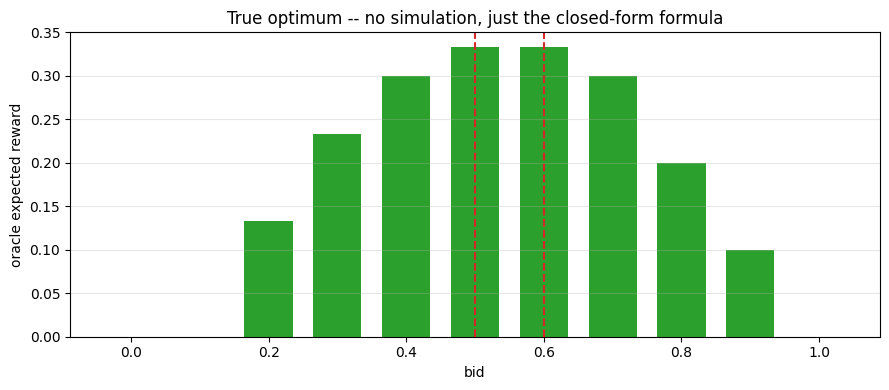

In [21]:
oracle_rewards = np.array([
    expected_reward_for_uniform_competing_bid(
        bid=float(b), value=VALUE, min_competing_bid=MIN_CB, max_competing_bid=MAX_CB,
        competing_bid_distribution=DIST, n_competitors=N_COMP,
    )
    for b in BIDS
])
optimal_bids = BIDS[np.isclose(oracle_rewards, oracle_rewards.max(), atol=1e-9)]
print(f"Oracle expected reward per bid: {dict(zip(BIDS, np.round(oracle_rewards, 4)))}")
print(f"True optimal bid(s): {optimal_bids} (a genuine tie on this discrete grid)")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(BIDS, oracle_rewards, width=0.07, color="#2ca02c")
for b in optimal_bids:
    ax.axvline(b, color="#d62728", linestyle="--", linewidth=1.5)
ax.set_xlabel("bid"); ax.set_ylabel("oracle expected reward")
ax.set_title("True optimum -- no simulation, just the closed-form formula")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

The optimum here is a genuine tie between bid 0.5 and bid 0.6 -- both give exactly 1/3 expected reward on
this discrete grid. Now let's see how close each algorithm's actual bidding gets to that answer key.

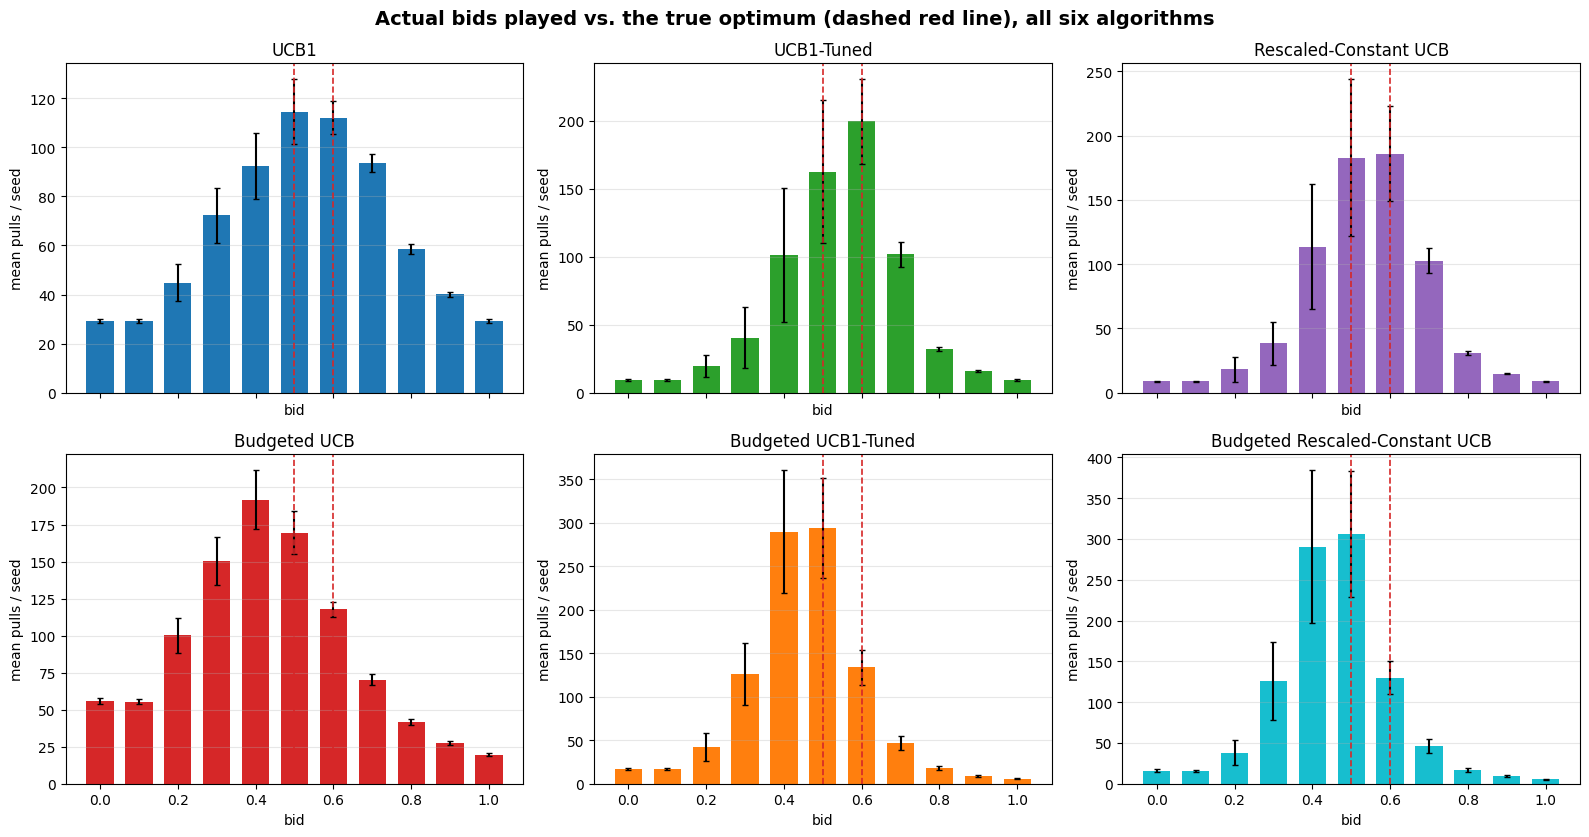

In [22]:
all_multi_results = {**multi_results_p1, **multi_results_p3_free, **multi_results_p3_budgeted}
all_algo_order = ["ucb1", "ucb1_tuned", "expected_reward_scaled_ucb",
                   "budgeted_ucb", "budgeted_ucb1_tuned", "budgeted_expected_reward_scaled_ucb"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharex=True)
for ax, name in zip(axes.flat, all_algo_order):
    counts = np.stack([r["arm_counts"] for r in all_multi_results[name]])
    mean, std = counts.mean(axis=0), counts.std(axis=0)
    ax.bar(BIDS, mean, width=0.07, yerr=std, color=COLORS[name], capsize=2)
    for b in optimal_bids:
        ax.axvline(b, color="#d62728", linestyle="--", linewidth=1.2)
    ax.set_title(LABELS[name], fontsize=12)
    ax.set_xlabel("bid"); ax.set_ylabel("mean pulls / seed")
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Actual bids played vs. the true optimum (dashed red line), all six algorithms",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

In [23]:
arm_stats_rows = []
uniform_baseline_pct = 100.0 / len(BIDS)
for name in all_algo_order:
    counts = np.stack([r["arm_counts"] for r in all_multi_results[name]])
    mean = counts.mean(axis=0)
    pct = mean / mean.sum() * 100.0
    top_index = int(np.argmax(mean))
    pct_on_optimum = float(pct[np.isin(BIDS, optimal_bids)].sum())
    arm_stats_rows.append({
        "algorithm": LABELS[name],
        "most-pulled bid": float(BIDS[top_index]),
        "% of pulls on most-pulled bid": round(float(pct[top_index]), 1),
        "% of pulls on the true optimum set {0.5, 0.6}": round(pct_on_optimum, 1),
        "uniform-random baseline %": round(uniform_baseline_pct, 1),
    })
arm_stats_df = pd.DataFrame(arm_stats_rows)
arm_stats_df

,algorithm,most-pulled bid,% of pulls on most-pulled bid,"% of pulls on the true optimum set {0.5, 0.6}",uniform-random baseline %
0,UCB1,0.5,16.0,31.6,9.1
1,UCB1-Tuned,0.6,28.5,51.7,9.1
2,Rescaled-Constant UCB,0.6,26.1,51.7,9.1
3,Budgeted UCB,0.4,19.2,28.7,9.1
4,Budgeted UCB1-Tuned,0.5,29.4,42.8,9.1
5,Budgeted Rescaled-Constant UCB,0.5,30.6,43.6,9.1


Every algorithm clearly concentrates its bids around the true optimum instead of spreading evenly across
all 11 bids (which would put about 9.1% on each one). Plain UCB1 puts 31.6% of its
pulls on the tied-optimal set {0.5, 0.6}; Budgeted UCB is similar at 28.7%. The two exploration
variants concentrate noticeably harder: UCB1-Tuned reaches 51.7% and the rescaled-constant
version 51.7% in the budget-free case, and the budgeted versions push even further, to
42.8% and 43.6%. This is the direct mechanism behind the lower regret we
saw earlier: the tuned/rescaled variants aren't discovering a different answer, they're converging on the
*same* answer with a tighter, more confident distribution.

## Extended check -- T = 10000, B = 3000: is regret actually sublinear?

This goes back to the question that kicked off this whole investigation: at T = 1000 it was genuinely hard
to tell by eye whether regret was growing sublinearly or not. So here's the same six algorithms, same
`rho = B/T = 0.3` ratio, just scaled 10x -- T = 10000, B = 3000 -- to get a much longer, clearer curve. Only
8 seeds this time to keep the runtime sane, and I'm only plotting cumulative pseudo-regret here (not the
full 2x2 panel), since that's the thing actually in question.

One thing to expect going in: the budget-free algorithms will still go bankrupt at roughly the *same
fraction* of the horizon as before, since how long the budget lasts depends on the budget-to-spending-rate
ratio, not on T directly -- and B was scaled by the same 10x as T. That means their curves should look
concave and flattening for a good ~7000 rounds (10x more actual learning than we got to see at T=1000),
then kink into a straight-line ramp once they go bankrupt -- same fair full-horizon accounting as
everywhere else in this notebook, not a sign they stopped learning. The budgeted algorithms, which never
go bankrupt, should stay concave the entire way -- that's the cleanest version of "yes, this is sublinear"
this notebook can show.

In [24]:
HORIZON_EXT = 10_000
INITIAL_BUDGET_EXT = 3_000.0
N_SEEDS_EXT = 8

ucb1_benchmark_ext, budgeted_benchmark_ext = compute_req1_benchmarks(
    bids=BIDS, value=VALUE, initial_budget=INITIAL_BUDGET_EXT, horizon=HORIZON_EXT,
    min_competing_bid=MIN_CB, max_competing_bid=MAX_CB,
    competing_bid_distribution=DIST, n_competitors=N_COMP,
)
print(f"T={HORIZON_EXT}, B={INITIAL_BUDGET_EXT} (same rho={INITIAL_BUDGET_EXT/HORIZON_EXT:.2f}) -> "
      f"UCB1 benchmark: {ucb1_benchmark_ext:.4f}, budget-feasible benchmark: {budgeted_benchmark_ext:.4f}")

T=10000, B=3000.0 (same rho=0.30) -> UCB1 benchmark: 0.3333, budget-feasible benchmark: 0.3250


In [25]:
multi_results_ext_free = {
    "ucb1": multi_seed_run(
        lambda s: UCB1(actions=BIDS, horizon=HORIZON_EXT), "ucb1", False,
        N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, ucb1_benchmark_ext,
    ),
    "ucb1_tuned": multi_seed_run(
        lambda s: UCB1Tuned(actions=BIDS, horizon=HORIZON_EXT), "ucb1_tuned", False,
        N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, ucb1_benchmark_ext,
    ),
    "expected_reward_scaled_ucb": multi_seed_run(
        lambda s: ExpectedRewardScaledUCB(actions=BIDS, horizon=HORIZON_EXT, max_expected_reward=ucb1_benchmark_ext),
        "expected_reward_scaled_ucb", False, N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, ucb1_benchmark_ext,
    ),
}
print("budget-free extended runs done:", {k: len(v) for k, v in multi_results_ext_free.items()})

budget-free extended runs done: {'ucb1': 8, 'ucb1_tuned': 8, 'expected_reward_scaled_ucb': 8}


In [26]:
multi_results_ext_budgeted = {
    "budgeted_ucb": multi_seed_run(
        lambda s: BudgetedUCB(actions=BIDS, horizon=HORIZON_EXT, initial_budget=INITIAL_BUDGET_EXT,
                               random_seed=s + 1_000_003),
        "budgeted_ucb", True, N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, budgeted_benchmark_ext,
    ),
    "budgeted_ucb1_tuned": multi_seed_run(
        lambda s: BudgetedUCB1Tuned(actions=BIDS, horizon=HORIZON_EXT, initial_budget=INITIAL_BUDGET_EXT,
                                     random_seed=s + 2_000_003),
        "budgeted_ucb1_tuned", True, N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, budgeted_benchmark_ext,
    ),
    "budgeted_expected_reward_scaled_ucb": multi_seed_run(
        lambda s: BudgetedExpectedRewardScaledUCB(actions=BIDS, horizon=HORIZON_EXT, initial_budget=INITIAL_BUDGET_EXT,
                                                    max_expected_reward=ucb1_benchmark_ext, random_seed=s + 3_000_003),
        "budgeted_expected_reward_scaled_ucb", True, N_SEEDS_EXT, BASE_ENV_SEED, INITIAL_BUDGET_EXT, HORIZON_EXT, budgeted_benchmark_ext,
    ),
}
print("budget-aware extended runs done:", {k: len(v) for k, v in multi_results_ext_budgeted.items()})

budget-aware extended runs done: {'budgeted_ucb': 8, 'budgeted_ucb1_tuned': 8, 'budgeted_expected_reward_scaled_ucb': 8}


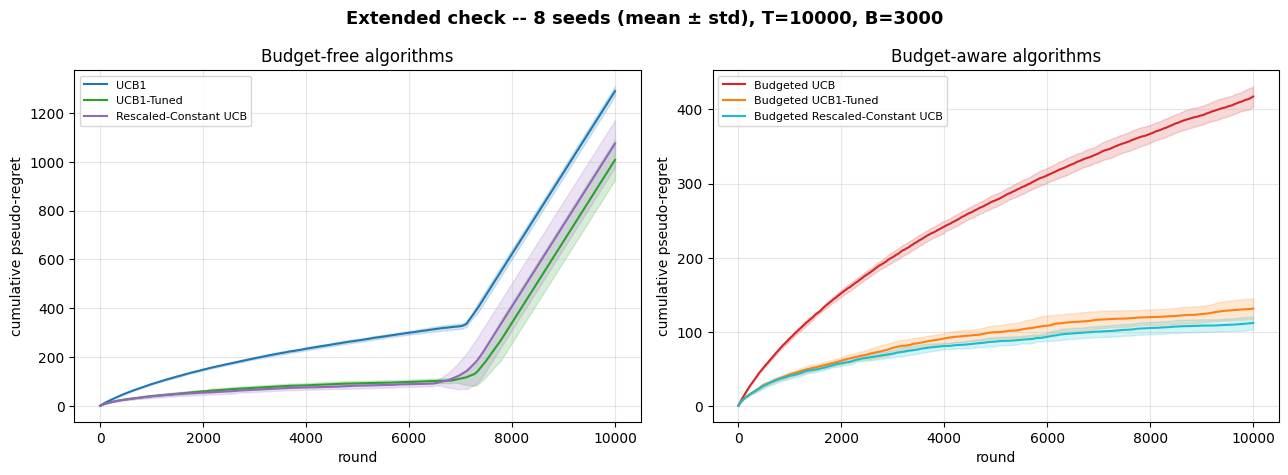

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=False)
groups = [
    (multi_results_ext_free, ["ucb1", "ucb1_tuned", "expected_reward_scaled_ucb"], axes[0], "Budget-free algorithms"),
    (multi_results_ext_budgeted, ["budgeted_ucb", "budgeted_ucb1_tuned", "budgeted_expected_reward_scaled_ucb"], axes[1], "Budget-aware algorithms"),
]
for data, names, ax, subtitle in groups:
    for name in names:
        agg = aggregate_multi(data[name])
        rounds = np.arange(1, agg["pseudo_regret"].shape[1] + 1)
        mean, std = agg["pseudo_regret"].mean(axis=0), agg["pseudo_regret"].std(axis=0)
        ax.plot(rounds, mean, color=COLORS[name], label=LABELS[name])
        ax.fill_between(rounds, mean - std, mean + std, color=COLORS[name], alpha=0.18)
    ax.set_xlabel("round"); ax.set_ylabel("cumulative pseudo-regret"); ax.set_title(subtitle)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle(f"Extended check -- {N_SEEDS_EXT} seeds (mean \u00b1 std), T={HORIZON_EXT}, B={INITIAL_BUDGET_EXT:.0f}",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

That's exactly the shape I expected. On the left, all three budget-free algorithms trace out a clearly
concave, flattening curve for about the first 7122 rounds (versus the roughly 700 rounds we got
to see at T=1000) before kinking into the straight-line ramp once they run out of budget -- ten times more
runway makes the "this is actually converging" story much easier to see with your own eyes, not just from
the regret number. On the right, the budgeted algorithms never hit that wall, and their curves stay concave
all the way out to round 10000: full-horizon pseudo-regret ends around **417**
(Budgeted UCB), **131** (Budgeted UCB1-Tuned), and **112** (Budgeted
rescaled-constant) -- versus a horizon 10x smaller, so on a per-round basis these are all landing at a much
smaller average regret per round than they were at T=1000. That's the sublinear signature this whole
notebook has been chasing since the very first version of this experiment.

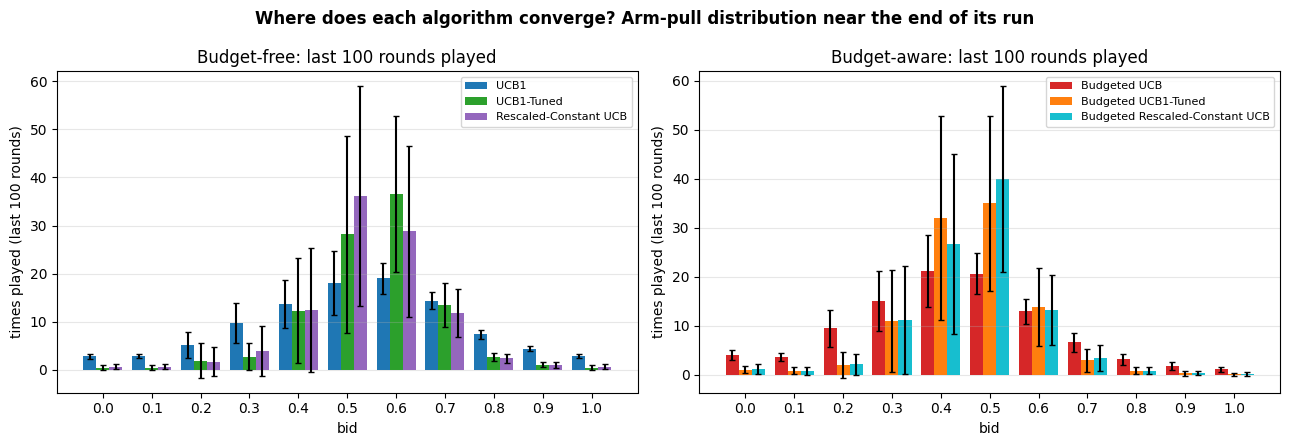

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
n_actions = len(BIDS)
groups = [
    (multi_results_p3_free, ["ucb1", "ucb1_tuned", "expected_reward_scaled_ucb"], axes[0], "Budget-free: last 100 rounds played"),
    (multi_results_p3_budgeted, ["budgeted_ucb", "budgeted_ucb1_tuned", "budgeted_expected_reward_scaled_ucb"], axes[1], "Budget-aware: last 100 rounds played"),
]
for source, names, ax, subtitle in groups:
    bar_width = 0.8 / len(names)
    for i, name in enumerate(names):
        counts = np.stack([r["last_100_counts"] for r in source[name]])
        mean, std = counts.mean(axis=0), counts.std(axis=0)
        ax.bar(np.arange(n_actions) + i * bar_width, mean, width=bar_width, yerr=std,
               color=COLORS[name], label=LABELS[name], capsize=2)
    ax.set_xticks(np.arange(n_actions) + bar_width * (len(names) - 1) / 2)
    ax.set_xticklabels([f"{b:.1f}" for b in BIDS])
    ax.set_xlabel("bid"); ax.set_ylabel("times played (last 100 rounds)"); ax.set_title(subtitle)
    ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
fig.suptitle("Where does each algorithm converge? Arm-pull distribution near the end of its run", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

This last one isn't strictly necessary, but it answers a question the regret numbers alone don't: does each
algorithm actually converge to the true best bid, 0.5 (tied with 0.6)? Looking at just the last 100 rounds
each algorithm actually got to play (not the full horizon -- for the budget-free ones that window is near
their bankruptcy point, not round 1000), all six put most of their weight in the 0.4-0.6 range, right where
the full-run arm-pull distribution above already showed, with the variants concentrating noticeably more
tightly than plain UCB1. That's the real mechanism behind the regret gap: UCB1-Tuned and the
rescaled-constant variant aren't finding a *different* answer, they're just settling on the *same* answer
faster.

## Summary

Across all three experiments, the same two-part story holds up. First: under a binding budget, whether an
algorithm is *aware* of the budget matters more than almost anything else -- plain UCB1 loses the vast
majority of its full-horizon regret simply to going bankrupt early and stopping mid-campaign, not to picking
worse arms. Budgeted UCB's LP-based pacing fixes that on its own, before any change to the exploration term.
Second: on top of that, UCB1-Tuned and the rescaled-constant variant both give a real, roughly-equal
improvement over canonical UCB1 by converging to the best arm faster -- but neither one comes with a proven
regret bound, so they're best presented as an empirical finding on top of the textbook algorithm, not a
replacement for it.